#  MLP

*NOTE*: In this tutorial we follow Bengio et al. NN architecture

Sources:
1. video: https://www.youtube.com/watch?v=TCH_1BHY58I&list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&index=3
2. paper: https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf

In [501]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [502]:
words = open("../data/names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [503]:
# build characters list from the whole dataset (and more)
chars = sorted(list(set("".join(words))))  # all unique characters in the dataset
se_ch = "."  # start / end character

# build character to integer lookup table
# note: used to place the character at correct cell in the 2D array

# starting from integer 1 (0 is reserved)
stoi = {c: i + 1 for i, c in enumerate(chars)}
# start / end characters number is zero
stoi[se_ch] = 0

# build integer to character lookup table
# note: used to find the index of a character in the 2D array
itos = {i: c for c, i in stoi.items()}

In [504]:
print(itos)
vocab_size = len(stoi)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [505]:
# compile the dataset for the NN

block_size = 3  # context length: how many characters we take to predict next one

X = []  # inputs - indexes for 3 chars
Y = []  # labels - index for output 1 char

for w in words:
    context = [0] * block_size  # starting with ... (0 in vocab is '.', a dot)
    # print(w)

    w = w + "."  # add end char
    for ch in w:
        ix = stoi[ch]  # index lookup
        X.append(context)
        Y.append(ix)
        # next context; moving window through the word, one char at a time
        # print(f'{"".join([itos[c] for c in context])} ---> {ch}')
        context = context[1:] + [ix]

# Create tensors
X = torch.tensor(X)
Y = torch.tensor(Y)

In [506]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

---
*00:53:20 splitting up the dataset into train/val/test splits and why*

In [507]:
# splitting dataset theory
# usually in production the dataset is split in different parts,
# so the model doesn't simply memorize the data, but train and actually do useful work.
# if this is not done, than the model learns the whole dataset during training,
# and simply produce from what it memorize

# the usual split is: 80 10 10
# 80% training data - for actual training
# 10% dev or validation data - for hyperparameters
# 10% test data - never use test data on training. NEVER!!!

In [508]:
# splitting dataset action


def build_dataset(words):
    block_size = 3  # context length: how many characters we take to predict next one

    X = []  # inputs - indexes for 3 chars
    Y = []  # labels - index for output 1 char

    for w in words:
        context = [0] * block_size  # starting with ... (0 in vocab is '.', a dot)
        # print(w)

        w = w + "."  # add end char
        for ch in w:
            ix = stoi[ch]  # index lookup
            X.append(context)
            Y.append(ix)
            # next context; moving window through the word, one char at a time
            # print(f'{"".join([itos[c] for c in context])} ---> {ch}')
            context = context[1:] + [ix]

    # Create tensors
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}; Y.shape: {Y.shape}")
    return X, Y


import random

random.seed(42)
random.shuffle(words)  # shuffle for better randomization
n1 = int(0.8 * len(words))  # 80% words
n2 = int(0.9 * len(words))  # 90% words

Xtr, Ytr = build_dataset(words[:n1]) # training set
Xdev, Ydev = build_dataset(words[n1:n2])  # dev / validation set
Xte, Yte = build_dataset(words[n2:])  # test set

X.shape: torch.Size([182625, 3]); Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 3]); Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 3]); Y.shape: torch.Size([22866])


In [509]:
len(words[:n1]), len(words[n1:n2]), len(words[n2:])

(25626, 3203, 3204)

In [510]:
# Creating embeddings lookup table for the characters vocabulary
seed = 2147483647
g = torch.Generator().manual_seed(seed)  # for deterministic output

# C lookup table is a vocab_size * dim size (e.g. 27 *2)
# Each line is an d items array of numbers - called embedding
# In other words, for each character in the vocabulary,
# we create a d size array of numbers

dim = 10  # embedding size
C = torch.randn((vocab_size, dim), generator=g)

In [511]:
# Lookup embeddings
# We'll take 3 chars in our NN as an input
# So for these 3 chars we need to input 3 embeddings simultaneously
# This why the emb exists - shape [vocab_size, input_size, embedding_size], e.g. [300K, 3, 2]
emb = C[X]
emb.shape, C.shape, X.shape

(torch.Size([228146, 3, 10]), torch.Size([27, 10]), torch.Size([228146, 3]))

In [512]:
# NN

# Note: We need to input all 3 characters once in our NN
# For that we can concatenate the 3 character embeddings into a single vector
# So we can interpret our input vector, as first layer of NN, thus W notation
# input size, e.g. 6 because: 3 input chars * 2 embedding size

input_size = block_size * dim  # inputs size
h_size = 200  # hidden layer outputs size
W1 = torch.randn((input_size, h_size))  # input_size input, 100 output
b1 = torch.randn(h_size)  # bias

In [513]:
# forward pass

# Note: Because of different dimensionality,
# we cannot multiply and add '@' in the first layer, e.g. emb @ W1 + b
# For that we need to 'arrange' the shapes

# We have:
# emb.shape, W1.shape
# Note: 32 here is 32 inputs, just a fraction of the input sequence,
# for easier development. Normally it's the size off all 3 char inputs from dataset.
# (torch.Size([32, 3, 2]), torch.Size([6, 100]))

# We want:
# [32, 6], [6, 100]

# One way torch.cat - concatenate.
# But this is not scalable.
# If we're to increase the number of input characters, this code breaks
ex_cat = torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1)  # [32, 6]

# Another way with unbind, more scalable
ex_cat_unbind = torch.cat(torch.unbind(emb, 1), 1)  # [32, 6] same as above

# Better, more efficient way is by doing it with view.
# .view doesn't create a new tensor in the memory (the other 2 do)
ex_view = emb.view(-1, input_size)  # !Our winner

ex_cat.shape, ex_cat_unbind.shape, ex_view.shape

(torch.Size([228146, 30]), torch.Size([228146, 30]), torch.Size([228146, 30]))

In [514]:
# check all 3 are equal
(ex_cat == ex_cat_unbind) & (ex_cat_unbind == ex_view)

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])

In [515]:
# first layer
# h = torch.tanh(emb.view(emb.shape[0], input_size) @ W1 + b1)
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
h.shape, h

(torch.Size([228146, 200]),
 tensor([[ 1.0000, -0.9871,  0.9987,  ...,  0.5629,  0.9971, -0.0258],
         [ 0.9999,  0.8328,  0.9731,  ...,  0.9998,  0.3638, -0.9581],
         [ 1.0000, -1.0000,  0.3452,  ..., -0.9978,  1.0000,  0.9687],
         ...,
         [ 0.9975,  0.3695, -0.8467,  ...,  0.8388,  0.1779, -0.9994],
         [ 1.0000, -0.9897, -0.9652,  ..., -0.7895, -0.9910,  0.9998],
         [ 1.0000,  0.9954, -0.6413,  ...,  0.9988,  0.9797, -0.9994]]))

In [516]:
# second layer
W2 = torch.randn((h_size, vocab_size))
b2 = torch.rand(vocab_size)

In [517]:
logits = h @ W2 + b2
logits.shape

torch.Size([228146, 27])

In [518]:
counts = logits.exp()

In [519]:
prob = counts / counts.sum(1, keepdim=True)
prob.shape

torch.Size([228146, 27])

In [520]:
loss = -prob[torch.arange(len(emb)), Y].log().mean()
loss

tensor(25.9305)

In [521]:
# --- make it respectable ---#

In [522]:
Xtr.shape, Ytr.shape  # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [523]:
g = torch.Generator().manual_seed(2147483647)  # for determinism

# NN
C = torch.randn((vocab_size, dim), generator=g, requires_grad=True)
W1 = torch.randn((input_size, h_size), generator=g, requires_grad=True)
b1 = torch.randn(h_size, generator=g, requires_grad=True)
W2 = torch.randn((h_size, vocab_size), generator=g, requires_grad=True)
b2 = torch.randn(vocab_size, generator=g, requires_grad=True)
parameters = [C, W1, b1, W2, b2]

In [524]:
# number of parameters in total
print("parameters:", sum(p.nelement() for p in parameters))

parameters: 11897


In [525]:
for p in parameters:
    p.requires_grad = True

In [526]:
# learning rate
# note - steps (1000) should be the same as iterations in the training, 
# because we're indexing the learning rate from lrs
#note 2 - we use these (lre, lrs) only to find a good learning rate; 
# also using plotting to find the best learning rate range

lre = torch.linspace(-3, 0, 1000)  # learning rate exponent
lrs = 10**lre

In [527]:
# track learning rate and loss
# note: tracking on 1000 steps, we found that the plot showed that,
# about -1 learning rate exponent the learning is best.
# learning rate exponent -1 is 0.1, so starting learning rate is 0.1 in our training; 
# we also may decrease the training rate to 0.01 or even 0.001 to slow down the learning rate, 
# when the loss is small enough so we don't blow it
# lri = []
lossi = []
stepi = []

In [528]:
# train
for i in range(200_000):

    # mini-batch construct (for efficiency)
    ix = torch.randint(0, Xtr.shape[0], (32,))  # 32 random indexes from X; shape (32)

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]  # learning rate
    # learning rate after tracking and analysis
    lr = 0.1 if i < 100_000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    # lri.append(lre[i])
    lossi.append(loss.log10().item())
    stepi.append(i)

print("loss:", loss.item())

loss: 2.3672938346862793


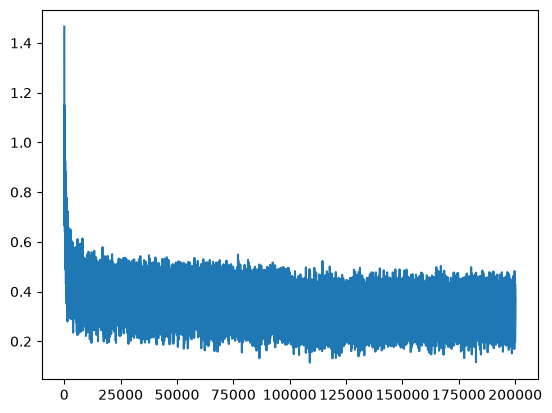

In [529]:
plt.plot(stepi, lossi)

In [530]:
# evaluate on dev set
# note: the model didn't see/train on dev set,
# so here we can evaluate the loss after training

emb = C[Xdev]
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1677, grad_fn=<NllLossBackward0>)

In [531]:
# evaluate on training set
# note: the model didn't train on training set

emb = C[Xtr]
h = torch.tanh(emb.view(-1, input_size) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1290, grad_fn=<NllLossBackward0>)

In [532]:
# plot learning rate and loss
# plt.plot(lri, lossi)
# plt.plot(stepi, lossi)

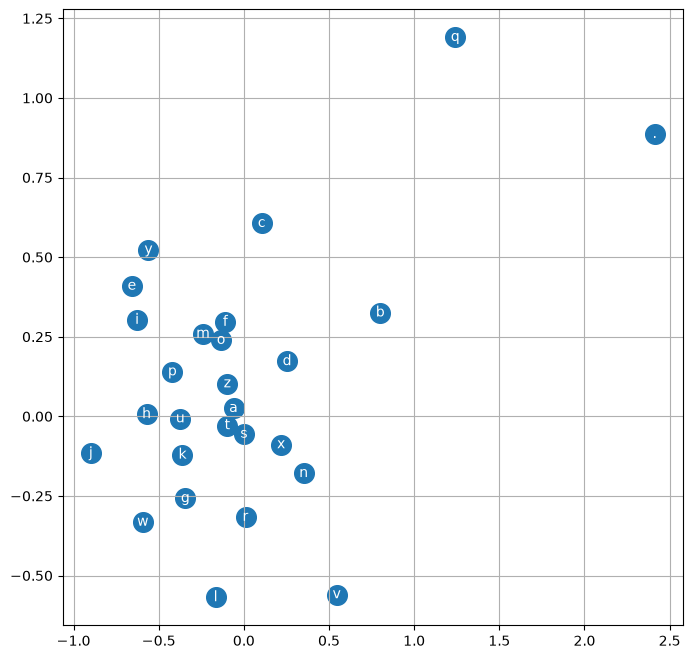

In [533]:
plt.figure(figsize=(8,8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [537]:
# sample from the model

g = torch.Generator().manual_seed(seed + 10)

for _ in range(20):
    
    out = [] # generated characters during a single iteration
    context = [0] * block_size # initialize with all ...
    
    while True:
        emb = C[torch.tensor([context])] # (1,block_size,dim)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        
        if ix == 0: # end character
            break # finish, go to the next iteration
    
    gen_name = "".join(itos[i] for i in out) # generated name in a single iteration
    print(gen_name)

carmah.
ambrilli.
kimrix.
taty.
sachysa.
jazhutefaresart.
kaeli.
ner.
kia.
chaiia.
kaleigh.
ham.
por.
desian.
sulin.
alianni.
watelo.
dearyxia.
kae.
pirrathe.
